In [9]:
from pathlib import Path
data_path=Path("")
image_path=data_path /"/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200"

In [10]:
import os
def check_data(dir_path):
  for dirpath,dirnames,filenames in os.walk(dir_path):
    print(f"# of directories:{len(dirnames)} and {len(filenames)} images in '{dirpath}'.")

In [11]:
check_data(image_path)

# of directories:2 and 0 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200'.
# of directories:10 and 0 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/australian_terrier'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/beagle'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/border_terrier'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/dingo'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/english_foxhound'.
# of directories:0 and 48 images in '/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test/golden_retriever'.
# of directories:0 and 48 images in '/kaggle/input/da

In [12]:
train_dir=image_path / "/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/train"
test_dir=image_path / "/kaggle/input/datasets/atilsamancioglu/imagewoof200/imagewoof200/test"

In [13]:
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [14]:
manual_transforms = transforms.Compose(
    [
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406],
                             std=[0.229,0.224,0.225])
    ]
)

In [15]:
NUM_WORKERS=os.cpu_count()
def create_dataloaders(
  train_dir:str,
  test_dir:str,
  transform:transforms.Compose,
  batch_size:int,
  num_workers:int=NUM_WORKERS
):
  train_data=datasets.ImageFolder(root=train_dir,
                                transform=transform,
                                target_transform=None)
  test_data=datasets.ImageFolder(root=test_dir,
                               transform=transform)
  class_names=train_data.classes

  train_dataloader=DataLoader(
      dataset=train_data,
      batch_size=batch_size,
      num_workers=num_workers,
      shuffle=True
  )
  test_dataloader=DataLoader(
      dataset=test_data,
      batch_size=batch_size,
      num_workers=num_workers,
      shuffle=False
  )
  return train_dataloader,test_dataloader,class_names

In [16]:
train_dataloader,test_dataloader,class_names=create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=manual_transforms,
    batch_size=32
)

In [17]:
train_dataloader

In [18]:
class_names

['australian_terrier',
 'beagle',
 'border_terrier',
 'dingo',
 'english_foxhound',
 'golden_retriever',
 'old_english_sheepdog',
 'rhodesian_ridgeback',
 'samoyed',
 'shih_tzu']

In [19]:
import torchvision

In [20]:
weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT

In [21]:
weights

EfficientNet_B0_Weights.IMAGENET1K_V1

In [22]:
auto_transforms=weights.transforms()

In [23]:
auto_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [24]:
train_dataloader,test_dataloader,class_names=create_dataloaders(train_dir=train_dir,
                                                                test_dir=test_dir,
                                                                transform=auto_transforms,
                                                                batch_size=32)

In [25]:
import torch
torch.cuda.is_available()

True

In [26]:
device="cuda"if torch.cuda.is_available() else "cpu"

In [27]:
device

'cuda'

In [28]:
model=torchvision.models.efficientnet_b0(weights=weights).to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s] 


In [29]:
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [30]:
!pip install torchinfo

In [31]:
from torchinfo import summary

In [32]:
summary(model=model,
        input_size=(32,3,224,224),
        col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
EfficientNet                                            [32, 3, 224, 224]         [32, 1000]                --                        True
├─Sequential: 1-1                                       [32, 3, 224, 224]         [32, 1280, 7, 7]          --                        True
│    └─Conv2dNormActivation: 2-1                        [32, 3, 224, 224]         [32, 32, 112, 112]        --                        True
│    │    └─Conv2d: 3-1                                 [32, 3, 224, 224]         [32, 32, 112, 112]        864                       True
│    │    └─BatchNorm2d: 3-2                            [32, 32, 112, 112]        [32, 32, 112, 112]        64                        True
│    │    └─SiLU: 3-3                                   [32, 32, 112, 112]        [32, 32, 112, 112]        --                        --
│    └─Sequential: 2-2  

In [33]:
for param in model.features.parameters():
  param.requires_grad=False

In [34]:
summary(model=model,
        input_size=(32,3,224,224),
        col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
EfficientNet                                            [32, 3, 224, 224]         [32, 1000]                --                        Partial
├─Sequential: 1-1                                       [32, 3, 224, 224]         [32, 1280, 7, 7]          --                        False
│    └─Conv2dNormActivation: 2-1                        [32, 3, 224, 224]         [32, 32, 112, 112]        --                        False
│    │    └─Conv2d: 3-1                                 [32, 3, 224, 224]         [32, 32, 112, 112]        (864)                     False
│    │    └─BatchNorm2d: 3-2                            [32, 32, 112, 112]        [32, 32, 112, 112]        (64)                      False
│    │    └─SiLU: 3-3                                   [32, 32, 112, 112]        [32, 32, 112, 112]        --                        --
│    └─Sequential

In [35]:
output_shape=len(class_names)

In [36]:
model.classifier =torch.nn.Sequential(
    torch.nn.Dropout(p=0.2,inplace=True),
    torch.nn.Linear(in_features=1280,out_features=output_shape,bias=True)
).to(device)

In [37]:
summary(model=model,
        input_size=(32,3,224,224),
        col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
EfficientNet                                            [32, 3, 224, 224]         [32, 10]                  --                        Partial
├─Sequential: 1-1                                       [32, 3, 224, 224]         [32, 1280, 7, 7]          --                        False
│    └─Conv2dNormActivation: 2-1                        [32, 3, 224, 224]         [32, 32, 112, 112]        --                        False
│    │    └─Conv2d: 3-1                                 [32, 3, 224, 224]         [32, 32, 112, 112]        (864)                     False
│    │    └─BatchNorm2d: 3-2                            [32, 32, 112, 112]        [32, 32, 112, 112]        (64)                      False
│    │    └─SiLU: 3-3                                   [32, 32, 112, 112]        [32, 32, 112, 112]        --                        --
│    └─Sequential

In [38]:
from torch import nn

In [39]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.001)

In [40]:
def train_step(model:torch.nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               optimizer:torch.optim.Optimizer,
               device:torch.device):
  model.train()

  train_loss=0
  train_acc=0

  for batch,(X,y) in enumerate(dataloader):
    X,y=X.to(device),y.to(device)

    y_pred=model(X)
    loss=loss_fn(y_pred,y)
    train_loss +=loss.item()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    y_pred_class=torch.argmax(torch.softmax(y_pred,dim=1),dim=1)
    train_acc +=(y_pred_class==y).sum().item() / len(y_pred)

  train_loss = train_loss/len(dataloader)
  train_acc = train_acc /len(dataloader)
  return train_loss,train_acc

In [41]:
def test_step(model:torch.nn.Module,
              dataloader:torch.utils.data.DataLoader,
              loss_fn:torch.nn.Module,
              device:torch.device):
  model.eval()

  test_loss=0
  test_acc=0

  with torch.inference_mode():
    for batch,(X,y) in enumerate(dataloader):
      X,y=X.to(device),y.to(device)

      test_pred_logits=model(X)
      loss=loss_fn(test_pred_logits,y)
      test_loss +=loss.item()

      test_pred_labels=test_pred_logits.argmax(dim=1)
      test_acc +=(test_pred_labels==y).sum().item() /len(test_pred_logits)

    test_loss=test_loss /len(dataloader)
    test_acc=test_acc /len(dataloader)
    return test_loss,test_acc

In [42]:
def train(model:torch.nn.Module,
          train_dataloader:torch.utils.data.DataLoader,
          test_dataloader:torch.utils.data.DataLoader,
          loss_fn:torch.nn.Module,
          optimizer:torch.optim.Optimizer,
          device:torch.device,
          epochs:int=10):
    results={
      "train_loss":[],
      "test_loss":[],
      "train_acc":[],
      "test_acc":[],
      }
    for epoch in range(epochs):
      train_loss,train_acc=train_step(model=model,
                                      dataloader=train_dataloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      device=device)
      test_loss,test_acc=test_step(model=model,
                                   dataloader=test_dataloader,
                                   loss_fn=loss_fn,
                                   device=device)
      print(
            f"Epoch:{epoch +1}|"
            f"Train Loss:{train_loss:.4f}|"
            f"Train Acc:{train_acc:.4f}|"
            f"Test Loss:{test_loss:.4f} |"
            f"Test Acc:{test_acc:.4f}"
        )

      results["train_loss"].append(train_loss.item() if isinstance(train_loss,torch.Tensor)else train_loss)
      results["train_acc"].append(train_acc.item() if isinstance(train_loss,torch.Tensor)else train_loss)
      results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
      results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)
    return results

In [43]:
results=train(model=model,
              train_dataloader=train_dataloader,
              test_dataloader=test_dataloader,
              optimizer=optimizer,
              loss_fn=loss_fn,
              device=device,
              epochs=10)

Epoch:1|Train Loss:1.4056|Train Acc:0.6538|Test Loss:0.7502 |Test Acc:0.8688
Epoch:2|Train Loss:0.7041|Train Acc:0.8457|Test Loss:0.5339 |Test Acc:0.8708
Epoch:3|Train Loss:0.5399|Train Acc:0.8755|Test Loss:0.4512 |Test Acc:0.8729
Epoch:4|Train Loss:0.4472|Train Acc:0.8929|Test Loss:0.4300 |Test Acc:0.8708
Epoch:5|Train Loss:0.4031|Train Acc:0.8958|Test Loss:0.4028 |Test Acc:0.8875
Epoch:6|Train Loss:0.3705|Train Acc:0.9028|Test Loss:0.3827 |Test Acc:0.8812
Epoch:7|Train Loss:0.3422|Train Acc:0.9107|Test Loss:0.3716 |Test Acc:0.8854
Epoch:8|Train Loss:0.3225|Train Acc:0.9157|Test Loss:0.3656 |Test Acc:0.8917
Epoch:9|Train Loss:0.3112|Train Acc:0.9152|Test Loss:0.3525 |Test Acc:0.8958
Epoch:10|Train Loss:0.2767|Train Acc:0.9286|Test Loss:0.3531 |Test Acc:0.8875


In [44]:
from PIL import Image

In [45]:
import matplotlib.pyplot as plt

In [46]:
from typing import List ,Tuple

In [47]:
def transform_predict(model:torch.nn.Module,
                      image_path:str,
                      class_names :List[str],
                      image_size:Tuple[int,int]=(224,224),
                      transform:torchvision.transforms=None,
                      device:torch.device=device
                      ):
  img=Image.open(image_path)
  if transform is not None:
    image_transform=transform
  else:
    image_transform=transforms.Compose([
        transforms.Resize(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406],
                             std=[0.229,0.224,0.225])
    ])

    model.to(device)

    model.eval()
    with torch.inference_mode():
      transformed_image=image_transform(img).unsqueeze(dim=0)
      target_image_pred =model(transformed_image.to(device))

    target_image_pred_probs=torch.softmax(target_image_pred,dim=1)
    target_image_pred_label=torch.argmax(target_image_pred_probs,dim=1)
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]},Prob: {target_image_pred_probs.max():.3f}")

In [48]:
custom_image_path=data_path /"/kaggle/input/datasets/onursvm/try-dogs/golden.jpg"

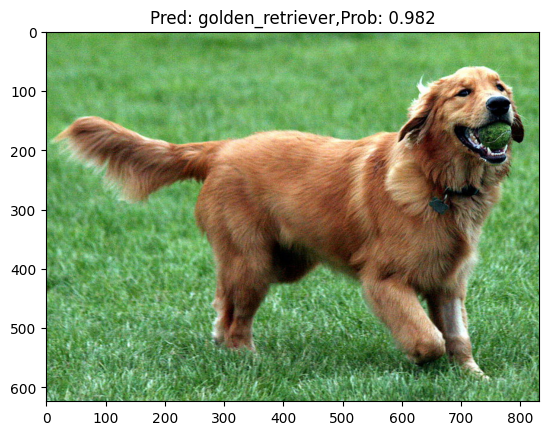

In [49]:
transform_predict(model,custom_image_path,class_names)

In [50]:
custom_image_path=data_path /"/kaggle/input/datasets/onursvm/try-dogs/shih_tzu.jpg"

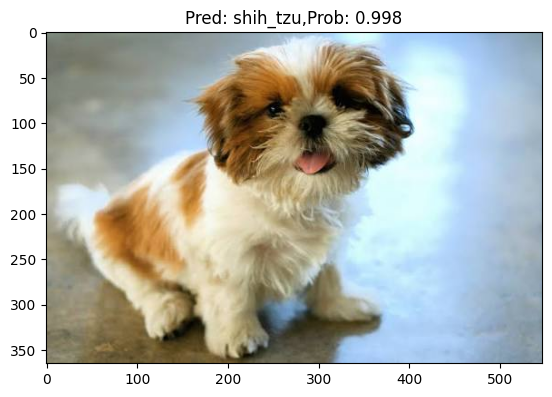

In [51]:
transform_predict(model,custom_image_path,class_names)

In [52]:
custom_image_path=data_path /"/kaggle/input/datasets/onursvm/try-dogs/images.jpg"

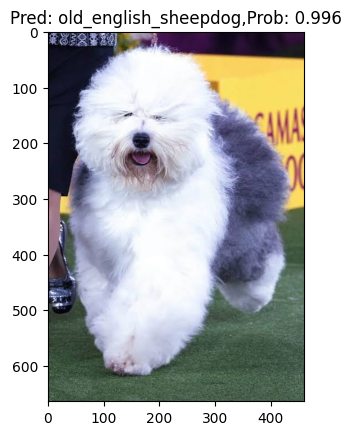

In [53]:
transform_predict(model,custom_image_path,class_names)

In [55]:
%config IPCompleter.use_jedi = False

In [57]:
import torchvision

In [61]:
weight_1=torchvision.models.MobileNet_V3_Large_Weights.DEFAULT

In [62]:
weight_1

MobileNet_V3_Large_Weights.IMAGENET1K_V2

In [63]:
auto_transform=weight_1.transforms()

In [64]:
auto_transform

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

In [67]:
train_dataloader,test_dataloader,class_names=create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=auto_transform,
    batch_size=32
)

In [68]:
model_1=torchvision.models.mobilenet_v3_large(weights=weight_1).to(device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 140MB/s] 


In [69]:
model_1

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [77]:
summary(model=model_1,
        input_size=(32,3,224,224),
       col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
MobileNetV3                                        [32, 3, 224, 224]         [32, 1000]                --                        True
├─Sequential: 1-1                                  [32, 3, 224, 224]         [32, 960, 7, 7]           --                        True
│    └─Conv2dNormActivation: 2-1                   [32, 3, 224, 224]         [32, 16, 112, 112]        --                        True
│    │    └─Conv2d: 3-1                            [32, 3, 224, 224]         [32, 16, 112, 112]        432                       True
│    │    └─BatchNorm2d: 3-2                       [32, 16, 112, 112]        [32, 16, 112, 112]        32                        True
│    │    └─Hardswish: 3-3                         [32, 16, 112, 112]        [32, 16, 112, 112]        --                        --
│    └─InvertedResidual: 2-2                       [32, 16,

In [79]:
for params in model_1.parameters():
    params.requires_grad=False

In [80]:
summary(model=model_1,
        input_size=(32,3,224,224),
       col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
MobileNetV3                                        [32, 3, 224, 224]         [32, 1000]                --                        False
├─Sequential: 1-1                                  [32, 3, 224, 224]         [32, 960, 7, 7]           --                        False
│    └─Conv2dNormActivation: 2-1                   [32, 3, 224, 224]         [32, 16, 112, 112]        --                        False
│    │    └─Conv2d: 3-1                            [32, 3, 224, 224]         [32, 16, 112, 112]        (432)                     False
│    │    └─BatchNorm2d: 3-2                       [32, 16, 112, 112]        [32, 16, 112, 112]        (32)                      False
│    │    └─Hardswish: 3-3                         [32, 16, 112, 112]        [32, 16, 112, 112]        --                        --
│    └─InvertedResidual: 2-2                       [32

In [74]:
auto_shape=len(class_names)

In [81]:
model_1.classifier[3]=nn.Linear(in_features=1280, out_features=auto_shape, bias=True).to(device)

In [82]:
summary(model=model_1,
        input_size=(32,3,224,224),
       col_names=["input_size","output_size","num_params","trainable"])

Layer (type:depth-idx)                             Input Shape               Output Shape              Param #                   Trainable
MobileNetV3                                        [32, 3, 224, 224]         [32, 10]                  --                        Partial
├─Sequential: 1-1                                  [32, 3, 224, 224]         [32, 960, 7, 7]           --                        False
│    └─Conv2dNormActivation: 2-1                   [32, 3, 224, 224]         [32, 16, 112, 112]        --                        False
│    │    └─Conv2d: 3-1                            [32, 3, 224, 224]         [32, 16, 112, 112]        (432)                     False
│    │    └─BatchNorm2d: 3-2                       [32, 16, 112, 112]        [32, 16, 112, 112]        (32)                      False
│    │    └─Hardswish: 3-3                         [32, 16, 112, 112]        [32, 16, 112, 112]        --                        --
│    └─InvertedResidual: 2-2                       [

In [84]:
optimizer1=torch.optim.Adam(params=model_1.parameters(),lr=0.001)

In [85]:
results1=train(model=model_1,
               train_dataloader=train_dataloader,
               test_dataloader=test_dataloader,
              loss_fn=loss_fn,
              optimizer=optimizer1,
              device=device,
              epochs=10)

Epoch:1|Train Loss:1.2641|Train Acc:0.7550|Test Loss:0.6315 |Test Acc:0.8979
Epoch:2|Train Loss:0.5381|Train Acc:0.8958|Test Loss:0.4373 |Test Acc:0.9208
Epoch:3|Train Loss:0.3963|Train Acc:0.9142|Test Loss:0.3734 |Test Acc:0.9167
Epoch:4|Train Loss:0.3291|Train Acc:0.9246|Test Loss:0.3415 |Test Acc:0.9250
Epoch:5|Train Loss:0.2984|Train Acc:0.9335|Test Loss:0.3233 |Test Acc:0.9229
Epoch:6|Train Loss:0.2530|Train Acc:0.9420|Test Loss:0.3074 |Test Acc:0.9167
Epoch:7|Train Loss:0.2325|Train Acc:0.9454|Test Loss:0.3005 |Test Acc:0.9208
Epoch:8|Train Loss:0.2048|Train Acc:0.9549|Test Loss:0.2929 |Test Acc:0.9208
Epoch:9|Train Loss:0.1936|Train Acc:0.9554|Test Loss:0.2869 |Test Acc:0.9229
Epoch:10|Train Loss:0.1830|Train Acc:0.9593|Test Loss:0.2849 |Test Acc:0.9167


In [87]:
custom_image_path1=data_path / "/kaggle/input/datasets/onursvm/try-dogs/golden.jpg"

In [88]:
custom_image_path2=data_path / "/kaggle/input/datasets/onursvm/try-dogs/images.jpg"

In [89]:
custom_image_path3=data_path / "/kaggle/input/datasets/onursvm/try-dogs/shih_tzu.jpg"

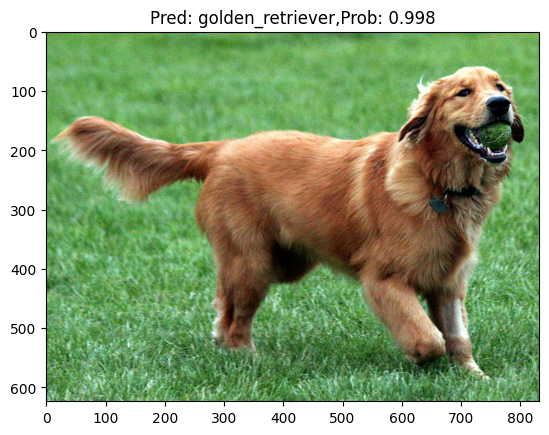

In [90]:
transform_predict(model=model_1,image_path=custom_image_path1,class_names=class_names)

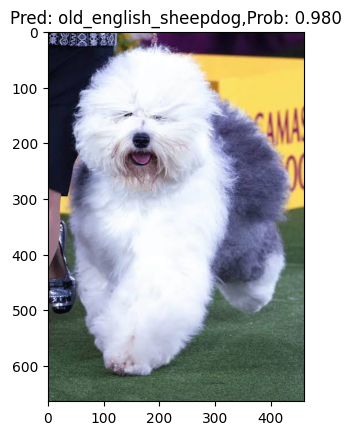

In [92]:
transform_predict(model=model_1,image_path=custom_image_path2,class_names=class_names)

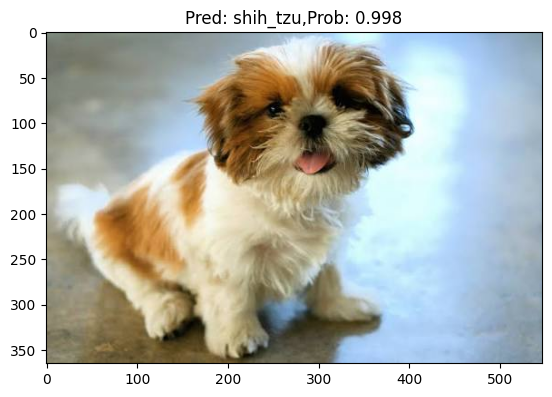

In [93]:
transform_predict(model=model_1,image_path=custom_image_path3,class_names=class_names)

In [95]:
torch.save(model_1.state_dict(),
          "/kaggle/working/mobilenetv3_imagewoof.pth")

In [96]:
%pip install -q onnx onnxscript onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 10.5 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 76.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.2/192.2 kB 10.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [97]:
model_1=model_1.cpu()
model_1.eval()

dummy_input=torch.randn(1,3,224,224)

torch.onnx.export(
    model_1,
    (dummy_input,),
    "/kaggle/working/mobilenetv3_imagewoof.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=18,
    dynamo=True
    
)
print("ONNX dosyası oluşturuldu")

[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MobileNetV3([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX dosyası oluşturuldu


In [99]:
path = "/kaggle/working/mobilenetv3_imagewoof.onnx"

print("Dosya var mı?", os.path.exists(path))
print("Boyut:", round(os.path.getsize(path) / 1024**2, 2), "MB")

Dosya var mı? True
Boyut: 0.33 MB


In [100]:

for file in os.listdir("/kaggle/working"):
    if "onnx" in file:
        path = os.path.join("/kaggle/working", file)
        print(file, round(os.path.getsize(path) / 1024**2, 2), "MB")

mobilenetv3_imagewoof.onnx 0.33 MB
mobilenetv3_imagewoof.onnx.data 16.03 MB


In [105]:
import onnxruntime as ort
import numpy as np

In [106]:
session=ort.InferenceSession(
    "/kaggle/working/mobilenetv3_imagewoof.onnx",
    providers=["CPUExecutionProvider"]
)
dummy_input=torch.randn(1,3,224,224)

with torch.inference_mode():
    pytorch_output=model_1(dummy_input).numpy()

onnx_output=session.run(
    None,
    {"input":dummy_input.numpy()}
)[0]

print("PyTorch tahmini:",pytorch_output.argmax())
print("ONNX tahmini:",onnx_output.argmax())
print("Maksimum sayısal fark:",np.max(np.abs(pytorch_output-onnx_output)))

PyTorch tahmini: 8
ONNX tahmini: 8
Maksimum sayısal fark: 7.748604e-06


In [107]:
import json
with open("/kaggle/working/class_names.json","w") as f:
    json.dump(class_names,f,indent=2)